In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
from np_detector.np_detector import np_detector
import matplotlib.pyplot as plt
from scipy.signal import lfilter

In [2]:
# Generate an AR(1) process with correlation rho, zero mean and variance process_var
samples = 100
process_var = 1.0
rho = 0.9
noise_var = process_var*(1.0-(rho**2))

rng = np.random.default_rng()

v = rng.normal(loc=0.0, scale=np.sqrt(noise_var), size=samples)

x = lfilter([1],[1, -rho], v)


In [3]:
beta_fa = 2
mu = 0.1
TH = beta_fa * np.sqrt(mu*process_var)

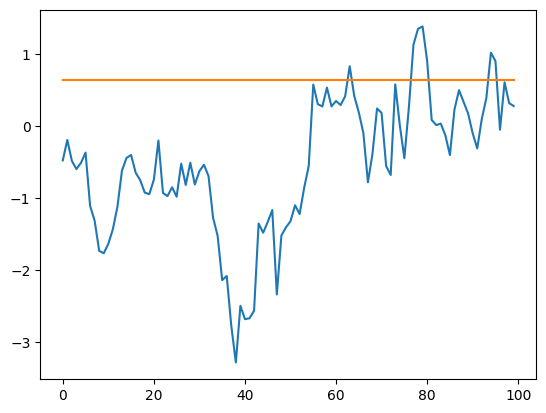

In [4]:
plt.plot(x)
plt.plot([0, samples-1], [TH*np.sqrt(process_var), TH*np.sqrt(process_var)])

In [5]:
detection = np_detector(x=x, beta_fa=beta_fa, mu=mu, xi=process_var, lambda_delta=1.0)

In [6]:
print(detection)

[False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False  True False False False False False False False False
 False False False False False  True  True  True  True False False False
 False False False False False False False False False False  True  True
 False False False False]
